In [2]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
import numpy as np
from tqdm import tqdm
from collections import defaultdict
from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_2bands import Moire
from Moire_v2 import Moire as Moire_single
import utils
import re

plt.rcParams.update({
    'figure.figsize': (6, 5),
    'figure.dpi': 120,          # crisper on screen
    'savefig.dpi': 300,         # high-res when saving
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.spines.top': True,   # remove top/right borders
    'axes.spines.right': True,
    'axes.grid': False,
    'lines.linewidth': 2,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

In [3]:
sys = Moire(theta_deg=2.0, psi_deg=26.0, V=6.6, n_shells=8)

# One Band

In [4]:
def parse_filename(name):
    pattern = re.compile(
        r"eval_MB_"
        r"(?P<grid>\d+x\d+)_"
        r"(?P<Ndn>\d+)Ndn_"
        r"(?P<Nup>\d+)Nup_"
        r"(?P<N2dn>\d+)N2dn_"
        r"(?P<N2up>\d+)N2up_"
        r"(?P<NEV>\d+)NEV(?P<Vm>\d+)_"
        r"(?P<band>\d+)b_"
        r"(?P<epsilon>\d+)0"
    )
    m = pattern.match(name)
    if not m:
        return None
    d = m.groupdict()
    # convert the purely-numeric fields to ints
    for k in ["Ndn", "Nup", "N2dn", "N2up", "NEV", "Vm", "band", "epsilon"]:
        d[k] = int(d[k])
    return d

def count_below(energies, Vm, E):
    e = energies[Vm]
    return int(np.sum(e < E))

def get_energies(path, target_epsilon):
    folder = Path(path)
    energies = defaultdict(list)

    for file in sorted(folder.rglob("eval_MB_*")):
        arr = np.atleast_2d(np.loadtxt(file))
        params = parse_filename(file.name)          # capture the return value
        if params["epsilon"] == target_epsilon:
            energies[params["Vm"]].append(arr[:, 1])

    energies = {vm: np.concatenate(arrs) for vm, arrs in energies.items()}
    energies = {vm: e - e.min() for vm, e in energies.items()}
    return energies

def get_spectrum(path, target_epsilon, target_V):
    folder = Path(path)
    spectrum = defaultdict(list)

    for file in sorted(folder.rglob("eval_MB_*")):
        arr = np.atleast_2d(np.loadtxt(file))
        params = parse_filename(file.name)          # capture the return value
        if params["epsilon"] == target_epsilon and params["Vm"] == target_V:
            for k_ind, e in zip(arr[:, 0], arr[:, 1]):
                spectrum[k_ind].append(np.atleast_1d(e))

    spectrum = {k_ind: np.concatenate(arrs, axis=0) for k_ind, arrs in spectrum.items()}
    spectrum = {k_ind: e - e.min() for k_ind, e in spectrum.items()}
    return spectrum

def find_min_e(path, target_epsilon, target_V):
    folder = Path(path)
    spectrum_Sz = defaultdict(list)

    for file in sorted(folder.rglob("eval_MB_*")):
        arr = np.atleast_2d(np.loadtxt(file))
        params = parse_filename(file.name)

        if params["epsilon"] == target_epsilon and params["Vm"] == target_V:
            Ndiff = params["Ndn"] - params["Nup"]
            spectrum_Sz[Ndiff].append(np.min(arr[:, 1]))

    return {Sz: np.array(es).min() for Sz, es in spectrum_Sz.items()}

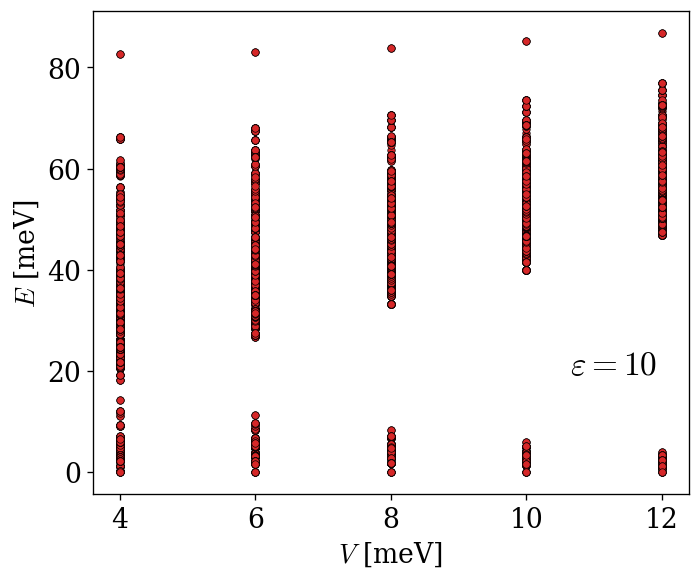

In [7]:
eps_val = 10
energies = get_energies(path="../EDDATA/ED_Results_1b_v2", target_epsilon=eps_val)
xs = np.concatenate([np.full(e.shape, vm) for vm, e in energies.items()])
ys = np.concatenate([e for e in energies.values()])

plt.figure()
plt.scatter(xs, ys, s=20, c="tab:red", edgecolor="k", linewidth=0.4)
plt.xlabel(r"$V$ [meV]", fontsize=16)
plt.xticks([4, 6, 8, 10, 12])
plt.text(0.8, 0.3, r"$\varepsilon="+str(eps_val)+"$", 
         transform=plt.gca().transAxes, fontsize=20, verticalalignment='top')
plt.ylabel(r"$E$ [meV]", fontsize=16)
plt.tight_layout()
plt.show()

In [7]:
count_below(energies, Vm=10, E=50.0)

905

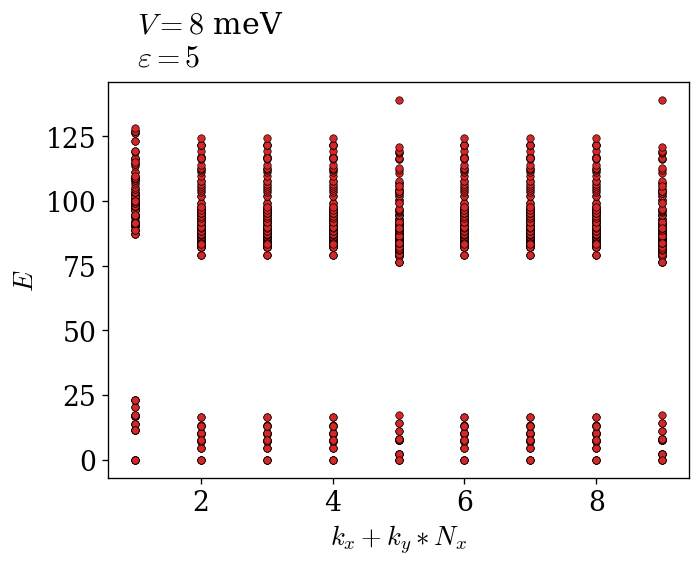

In [8]:
V_val = 8
eps_val = 5

energies = get_spectrum(path="../EDDATA/ED_Results_1b_v2", target_epsilon=eps_val, target_V=V_val)
xs = np.concatenate([np.full(e.shape, vm) for vm, e in energies.items()])
ys = np.concatenate([e for e in energies.values()])

plt.figure()
plt.scatter(xs, ys, s=20, c="tab:red", edgecolor="k", linewidth=0.4)
plt.xlabel(r"$k_x + k_y*N_x$", fontsize=16)
plt.ylabel(r"$E$", fontsize=16)
plt.text(0.05, 1.18, r"$V="+str(V_val)+"$ meV" + "\n" + r"$\varepsilon="+str(eps_val)+"$", 
         transform=plt.gca().transAxes, fontsize=18, verticalalignment='top')
plt.tight_layout()
plt.show()

Text(0.5, 1.0, '$\\varepsilon=5$')

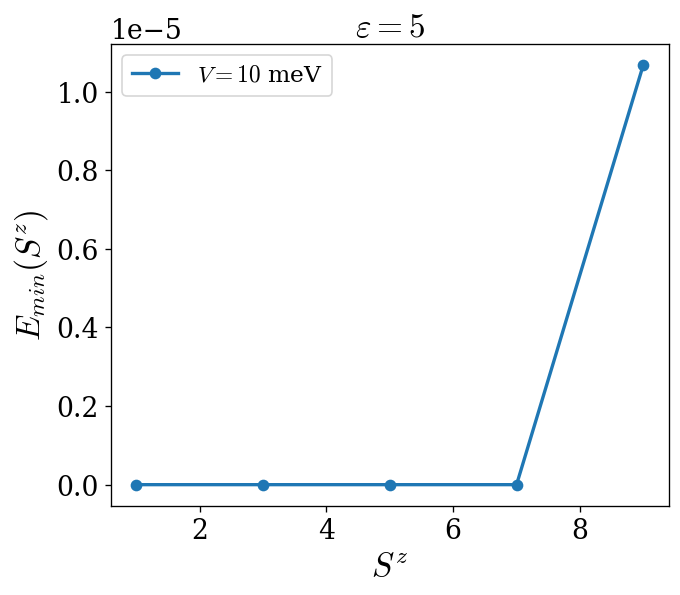

In [9]:
eps_val = 5

V_list = [10]

plt.figure()

for vv in V_list:

    V_val = vv
    Sz_dict = find_min_e(path="../EDDATA/ED_Results_1b_v2", target_epsilon=eps_val, target_V=V_val)

    sz = sorted(Sz_dict)                        # sorted keys
    e_min = [Sz_dict[s] for s in sz]            # matching min energies

    minimum = min(e_min)
    e_min = [e - minimum for e in e_min]  # shift energies to start from zero
    
    plt.plot(sz, e_min, "o-", label=r"$V="+str(V_val)+"$ meV")                   # markers + line
    plt.xlabel(r"$S^z$", fontsize=20)
    plt.ylabel("$E_{min}(S^z)$", fontsize=20)

plt.legend(loc="upper left", fontsize=14)
plt.title(r"$\varepsilon="+str(eps_val)+"$", fontsize=20, verticalalignment='top')

# Two Band

In [11]:
eps_val = 15
energies = get_energies(path="../EDDATA/ED_Results_2b", target_epsilon=eps_val)
xs = np.concatenate([np.full(e.shape, vm) for vm, e in energies.items()])
ys = np.concatenate([e for e in energies.values()])

plt.figure()
plt.scatter(xs, ys, s=20, c="tab:red", edgecolor="k", linewidth=0.4)
plt.xlabel(r"$V$ [meV]", fontsize=16)
plt.xticks([6, 8, 10, 12])
plt.text(0.75, 0.5, r"$\varepsilon="+str(eps_val)+"$", 
         transform=plt.gca().transAxes, fontsize=20, verticalalignment='top')
plt.ylabel(r"$E$", fontsize=16)
plt.tight_layout()
plt.show()

ValueError: need at least one array to concatenate

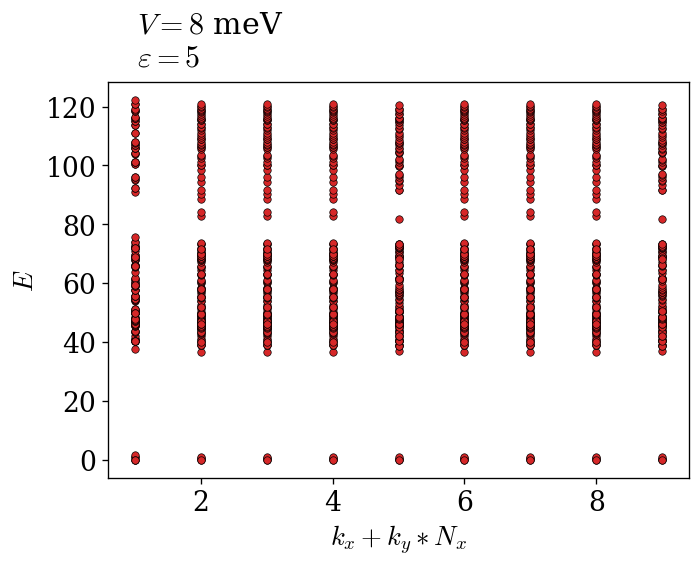

In [12]:
eps_val = 5
V_val = 8
energies = get_spectrum(path="../EDDATA/ED_Results_2b", target_epsilon=eps_val, target_V=V_val)
xs = np.concatenate([np.full(e.shape, vm) for vm, e in energies.items()])
ys = np.concatenate([e for e in energies.values()])

plt.figure()
plt.scatter(xs, ys, s=20, c="tab:red", edgecolor="k", linewidth=0.4)
plt.xlabel(r"$k_x + k_y*N_x$", fontsize=16)
plt.text(0.05, 1.18, r"$V="+str(V_val)+"$ meV" + "\n" + r"$\varepsilon="+str(eps_val)+"$", 
         transform=plt.gca().transAxes, fontsize=18, verticalalignment='top')
plt.ylabel(r"$E$", fontsize=16)
plt.tight_layout()
plt.show()

Text(0.85, 0.5, '$\\varepsilon=10$')

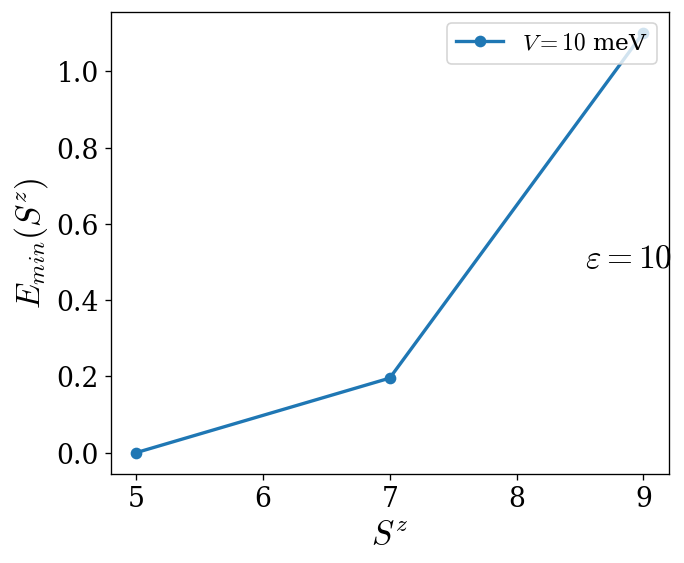

In [13]:
eps_val = 10

V_list = [10]

plt.figure()

for vv in V_list:

    V_val = vv
    Sz_dict = find_min_e(path="../EDDATA/ED_Results_2b", target_epsilon=eps_val, target_V=V_val)

    sz = sorted(Sz_dict)                        # sorted keys
    e_min = [Sz_dict[s] for s in sz]            # matching min energies

    minimum = min(e_min)
    e_min = [e - minimum for e in e_min]  # shift energies to start from zero
    
    plt.plot(sz, e_min, "o-", label=r"$V="+str(V_val)+"$ meV")                   # markers + line
    plt.xlabel(r"$S^z$", fontsize=20)
    plt.ylabel("$E_{min}(S^z)$", fontsize=20)
    # plt.tight_layout()
    # plt.show()
plt.legend(loc="upper right", fontsize=14)
plt.text(0.85, 0.5, r"$\varepsilon="+str(eps_val)+"$", 
        transform=plt.gca().transAxes, fontsize=20, verticalalignment='top')

Text(0.1, 0.5, '$\\varepsilon=10$')

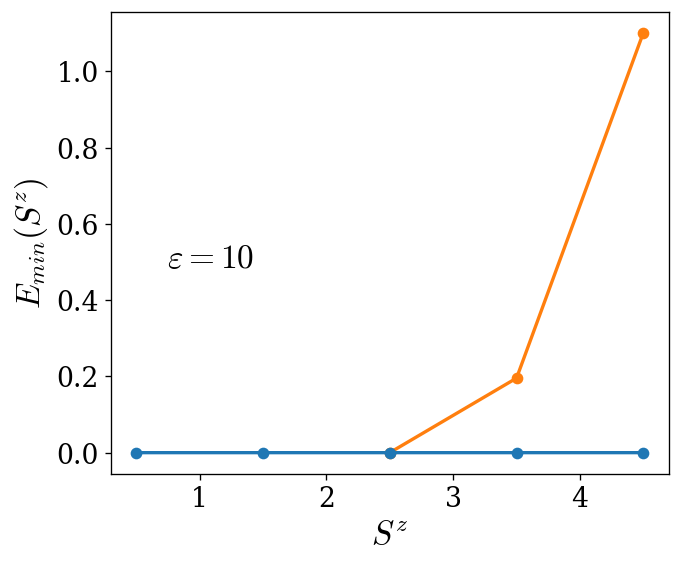

In [8]:
eps_val = 5

V_list = [10]

plt.figure()

for vv in V_list:

    V_val = vv
    Sz_dict = find_min_e(path="../EDDATA/ED_Results_1b_v2", target_epsilon=eps_val, target_V=V_val)

    sz = sorted(Sz_dict)                        # sorted keys
    e_min = [Sz_dict[s] for s in sz]            # matching min energies

    minimum = min(e_min)
    e_min = [e - minimum for e in e_min]  # shift energies to start from zero
    
    plt.plot([s / 2 for s in sz], e_min, "o-", label=r"$V="+str(V_val)+"$ meV")                   # markers + line
    plt.xlabel(r"$S^z$", fontsize=20)
    plt.ylabel("$E_{min}(S^z)$", fontsize=20)

eps_val = 10

V_list = [10]


for vv in V_list:

    V_val = vv
    Sz_dict = find_min_e(path="../EDDATA/ED_Results_2b", target_epsilon=eps_val, target_V=V_val)

    sz = sorted(Sz_dict)                        # sorted keys
    e_min = [Sz_dict[s] for s in sz]            # matching min energies

    minimum = min(e_min)
    e_min = [e - minimum for e in e_min]  # shift energies to start from zero
    
    plt.plot([s / 2 for s in sz], e_min, "o-", label=r"$V="+str(V_val)+"$ meV", zorder=0)                   # markers + line
    plt.xlabel(r"$S^z$", fontsize=20)
    plt.ylabel("$E_{min}(S^z)$", fontsize=20)
    # plt.tight_layout()
    # plt.show()
plt.text(0.1, 0.5, r"$\varepsilon="+str(eps_val)+"$", 
        transform=plt.gca().transAxes, fontsize=20, verticalalignment='top')